<a href="https://colab.research.google.com/github/brittanybee-alt/Updated-Capstone-Project---Brittany-Barrion/blob/main/DC_BB_Capstone_Two_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone Two: Exploratory Data Analysis
## Where You Grow Up Matters: Predicting Adult Income for Low-Income Children in the DC Region

**Project question:** Which neighborhood characteristics best predict adult income for children raised in low-income families in the DC metro area?

### Data Source
All data comes from **The Opportunity Atlas** (Opportunity Insights and the U.S. Census Bureau):

**[The Opportunity Atlas: household income at age 35 for children raised in low-income families, DC region](https://www.opportunityatlas.org/?%7B%22mapping%22%3A%22kfr%22%2C%22dataToggles%22%3A%7B%22parentIncome%22%3A%22p25%22%2C%22childRace%22%3A%22rP%22%2C%22childGender%22%3A%22gP%22%2C%22cohortTimeline%22%3A%22e%22%7D%2C%22compareDataToggles%22%3A%7B%22parentIncome%22%3A%22pall%22%2C%22childRace%22%3A%22rP%22%2C%22childGender%22%3A%22gP%22%2C%22cohortTimeline%22%3A%22e%22%7D%2C%22selectedChapterId%22%3A%22chapter1%22%2C%22compareFeatures%22%3A%22loc%22%2C%22selectedFeatureByID%22%3A11001010200%2C%22filters%22%3A%5B%5D%2C%22mode%22%3A%22standardMode%22%2C%22mapBounds%22%3A%5B%5B-77.29824387656735%2C38.72686964592006%5D%2C%5B-76.79125493105334%2C39.0687791383437%5D%5D%2C%22floatingPanelIsMinimized%22%3Afalse%2C%22showStoryMarkers%22%3Atrue%2C%22showHistogram%22%3Afalse%2C%22propertyShownOnMap%22%3A%22kfr_rP_gP_p25_e%22%7D)**

Two Census-tract-level files were downloaded from this map view and joined in the Data Wrangling notebook:
- `shown_tract_kfr_rP_gP_p25.csv`: average household income at age 35 for children whose parents were at the 25th income percentile (the **target**)
- `shown_tract_allCharacteristics.csv`: neighborhood characteristics by tract (the **predictors**)

### Goal
Explore the relationships of all features and understand how they compare to the response variable, `income_age35`.

**Input:** `data/processed/dc_tracts_clean.csv` (752 tracts × 17 columns, no missing values), the output of the Data Wrangling notebook.

**Steps (following the outline):**
1. Build data profiles and tables, including inferential statistics
2. Explore data relationships with data visualization
3. Feature selection and engineering
4. Answers to the outline's four questions

### Setup
**In Google Colab:** upload `dc_tracts_clean.csv` into a `data/processed` folder (Files panel on the left), then run the cells below.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
os.makedirs('figures', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)

df = pd.read_csv('/content/dc_tracts_clean.csv', dtype={'tract': str})
print(df.shape)
df.head()

(752, 17)


,tract,name,state,county,income_age35,median_rent,median_hh_income_2016,median_hh_income_1990,poverty_rate,frac_college_grad,frac_nonwhite,frac_foreign_born,frac_single_parents,pop_density,job_density,frac_short_commute,census_response_rate
0,51059480203,"Tysons, VA",VA,"Fairfax County, VA",69199.0,2138.0,90366.0,128382,0.0673,0.6614,0.3958,0.6029,0.1672,14264.0,44042.0,0.1916,76.2
1,24031701002,"Rockville, MD",MD,"Montgomery County, MD",69034.0,3193.0,200965.0,169391,0.0262,0.8069,0.2914,0.2444,0.0787,3554.0,1835.0,0.1747,88.3
2,51013100400,"Arlington, VA",VA,"Arlington County, VA",68322.0,3501.0,202909.0,162342,0.0286,0.8635,0.1214,0.1138,0.0941,2358.0,120.5,0.2106,91.2
3,51013101601,"North Highland, Arlington, VA",VA,"Arlington County, VA",65785.0,1982.0,119122.0,74114,0.1455,0.8462,0.2323,0.1876,0.2963,4899.0,2037.0,0.1230,79.5
4,51510200702,"Eisenhower East, Alexandria, VA",VA,"Alexandria city, VA",64583.0,2186.0,110481.0,64247,0.0222,0.8253,0.3072,0.1373,0.4101,8445.0,13782.0,0.1798,82.1


In [2]:
TARGET = 'income_age35'
features = [c for c in df.select_dtypes('number').columns if c != TARGET]
print('Target:', TARGET)
print(len(features), 'numeric features:', features)
print('Categorical columns: state, county')

Target: income_age35
12 numeric features: ['median_rent', 'median_hh_income_2016', 'median_hh_income_1990', 'poverty_rate', 'frac_college_grad', 'frac_nonwhite', 'frac_foreign_born', 'frac_single_parents', 'pop_density', 'job_density', 'frac_short_commute', 'census_response_rate']
Categorical columns: state, county


## 1. Build Data Profiles and Tables

### Profile of every numeric column
For each column: center (mean, median), spread (standard deviation, min, max), and shape (**skewness**). A skew near 0 means a roughly symmetric distribution. Above about 1, or below -1, means a long tail that may need a transform.

In [3]:
profile = df[[TARGET] + features].describe().T
profile['median'] = df[[TARGET] + features].median()
profile['skew'] = df[[TARGET] + features].skew()
profile = profile[['mean', 'median', 'std', 'min', 'max', 'skew']].round(3)
profile.sort_values('skew', key=abs, ascending=False)

,mean,median,std,min,max,skew
job_density,5040.740,1071.000,14858.046,0.000,177464.000,6.838
frac_short_commute,0.126,0.118,0.069,0.000,0.704,3.157
pop_density,9345.344,6421.000,9345.035,85.780,66900.000,2.419
poverty_rate,0.105,0.078,0.096,0.002,0.695,2.095
median_hh_income_1990,87444.848,82629.500,37105.614,11176.000,272105.000,1.109
median_hh_income_2016,98297.565,92247.500,46829.807,14509.000,246886.000,0.891
frac_single_parents,0.329,0.275,0.238,0.000,1.000,0.845
median_rent,1750.248,1693.500,594.978,241.000,3501.000,0.705
frac_foreign_born,0.231,0.205,0.150,0.000,0.711,0.675
census_response_rate,78.959,79.400,7.023,49.000,92.600,-0.631


**What the profile shows:**
- **`job_density` (skew 6.8) and `pop_density` (skew 2.4)** are very right-skewed: a few downtown tracts have extremely high values. They're the strongest candidates for a log transform (Section 3).
- **`frac_short_commute` (3.2) and `poverty_rate` (2.1)** are also right-skewed: most tracts have low values, with a long tail of high ones.
- **The target, `income_age35`, is only mildly skewed (0.43).** Its mean (\$36,668) is a little above its median (\$35,838).

### Profile tables by subgroup: state
The project covers three jurisdictions, so the first subgroup question is whether adult income for low-income children differs across them.

In [4]:
state_profile = df.groupby('state')[TARGET].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(0)
state_profile

,count,mean,median,std,min,max
state,,,,,,
DC,175,28266.0,26618.0,6986.0,19515.0,52982.0
MD,304,35160.0,33668.0,7984.0,21019.0,69034.0
VA,273,43734.0,43219.0,7803.0,26088.0,69199.0


In [5]:
# Neighborhood characteristics also differ by state
df.groupby('state')[['poverty_rate', 'frac_single_parents', 'frac_nonwhite', 'median_rent',
                     'median_hh_income_1990']].mean().round(3)

,poverty_rate,frac_single_parents,frac_nonwhite,median_rent,median_hh_income_1990
state,,,,,
DC,0.187,0.458,0.688,1410.863,58006.743
MD,0.091,0.365,0.724,1692.015,92292.743
VA,0.068,0.206,0.418,2032.648,100917.040


Children from low-income families who grew up in **Virginia tracts earn about \$15,500 more at age 35 than those from DC tracts** (\$43,734 vs. \$28,266 on average), with Maryland in between (\$35,160). The neighborhood characteristics differ a lot by state too: DC tracts have higher poverty and single-parent rates on average. Section 1's tests check whether the gaps are larger than chance would explain.

### Profile table by subgroup: poverty level (binning)
To see how the target changes across neighborhood poverty levels, I **bin** `poverty_rate` into four groups. This binned column is used only for exploring the data. It isn't kept as a model feature, because the model can use the exact poverty rate.

In [6]:
df['poverty_group'] = pd.cut(df['poverty_rate'], bins=[0, 0.05, 0.10, 0.20, 1.0],
                             labels=['Under 5%', '5-10%', '10-20%', 'Over 20%'], include_lowest=True)
df.groupby('poverty_group', observed=True)[TARGET].agg(['count', 'mean', 'median']).round(0)

,count,mean,median
poverty_group,,,
Under 5%,257,42435.0,42174.0
5-10%,209,37250.0,37280.0
10-20%,192,32812.0,32596.0
Over 20%,94,27487.0,24414.0


Adult income falls steadily as neighborhood poverty rises. Children from low-income families in tracts with **under 5% poverty earn about \$42,400** at 35, compared with **about \$27,500 in tracts with over 20% poverty**, a gap of roughly \$15,000.

### Anything abnormal?
**Outliers in the target:** I use the 1.5 × IQR rule to flag unusually high or low incomes.

In [7]:
q1, q3 = df[TARGET].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df[TARGET] < low) | (df[TARGET] > high)]
print(f'Outlier bounds: below ${low:,.0f} or above ${high:,.0f}')
print('Number of outliers:', len(outliers))
outliers[['tract', 'name', 'state', TARGET, 'poverty_rate', 'median_rent']]

Outlier bounds: below $7,649 or above $64,890
Number of outliers: 4


,tract,name,state,income_age35,poverty_rate,median_rent
0,51059480203,"Tysons, VA",VA,69199.0,0.0673,2138.0
1,24031701002,"Rockville, MD",MD,69034.0,0.0262,3193.0
2,51013100400,"Arlington, VA",VA,68322.0,0.0286,3501.0
3,51013101601,"North Highland, Arlington, VA",VA,65785.0,0.1455,1982.0


Only 4 tracts are outliers, all on the high side (above about \$64,900): Tysons, Rockville, Arlington and North Highland. These are real, well-off Northern Virginia and Montgomery County neighborhoods with low poverty, not data errors, so **they're kept**. Removing them would hide exactly the kind of high-opportunity neighborhoods the project is trying to understand.

Other unusual results noted in Data Wrangling: `median_rent` and `median_hh_income_2016` are top-coded by the Census in the most expensive tracts, so their highest values are understated.

### Inferential statistics
I form and test three sets of hypotheses. I use a significance level of **α = 0.05**. The p-value is the probability of seeing a result at least as extreme as this one if the null hypothesis were true.

**First, is the target normally distributed?** Many tests assume normality, so this decides which tests fit best.
- **H₀:** `income_age35` is normally distributed.
- **H₁:** it is not normally distributed.

In [8]:
stat, p = stats.shapiro(df[TARGET])
print(f'Shapiro-Wilk: W = {stat:.4f}, p = {p:.2e}')

Shapiro-Wilk: W = 0.9769, p = 1.60e-09


**Result:** p is far below 0.05, so I **reject H₀**: the target isn't perfectly normal (it's mildly right-skewed). With 752 tracts, the tests below are still reliable, but I back up each one with a **non-parametric** version that doesn't assume normality.

#### Hypothesis 1: Is each feature correlated with the target?
For each feature:
- **H₀:** no linear relationship with `income_age35` (Pearson r = 0)
- **H₁:** there is a linear relationship (r ≠ 0)

I report **Pearson's r** (linear relationship) and **Spearman's ρ** (rank-based, so it's robust to skew and outliers). Because I'm running 12 tests at once, I use a stricter **Bonferroni** threshold of 0.05 / 12 ≈ 0.004 to avoid false positives.

In [9]:
corr_tests = []
for col in features:
    r, p_r = stats.pearsonr(df[col], df[TARGET])
    rho, p_rho = stats.spearmanr(df[col], df[TARGET])
    corr_tests.append({'feature': col, 'pearson_r': r, 'pearson_p': p_r,
                       'spearman_rho': rho, 'spearman_p': p_rho})

bonferroni = 0.05 / len(features)
corr_table = pd.DataFrame(corr_tests).set_index('feature')
corr_table['significant'] = corr_table['pearson_p'] < bonferroni
corr_table = corr_table.sort_values('pearson_r', key=abs, ascending=False)
corr_table.round(4)

,pearson_r,pearson_p,spearman_rho,spearman_p,significant
feature,,,,,
frac_nonwhite,-0.6536,0.0000,-0.6760,0.0000,True
frac_single_parents,-0.6411,0.0000,-0.6364,0.0000,True
median_hh_income_1990,0.6406,0.0000,0.6804,0.0000,True
median_rent,0.6126,0.0000,0.6200,0.0000,True
median_hh_income_2016,0.6107,0.0000,0.6247,0.0000,True
frac_college_grad,0.5459,0.0000,0.5493,0.0000,True
poverty_rate,-0.5123,0.0000,-0.5560,0.0000,True
census_response_rate,0.4567,0.0000,0.4919,0.0000,True
frac_foreign_born,0.3434,0.0000,0.4536,0.0000,True


**Result:** I **reject H₀ for 11 of the 12 features**. Each has a statistically significant relationship with adult income, even at the strict Bonferroni level.
- **Strongest relationships (|r| ≈ 0.61-0.65):**
  - negative: `frac_nonwhite` and `frac_single_parents`
  - positive: `median_hh_income_1990`, `median_rent` and `median_hh_income_2016`
- **Moderate:** `frac_college_grad` (+0.55), `poverty_rate` (-0.51) and `census_response_rate` (+0.46)
- **Weaker:** `frac_foreign_born` (+0.34), `pop_density` and `frac_short_commute`
- **Not significant: `job_density`** (r ≈ 0.03, p ≈ 0.43). I **fail to reject H₀**: there's no evidence that how many jobs are in a tract relates to the adult income of children who grew up there.

**A note on `frac_nonwhite`:** this feature describes the neighborhood, not any individual child, since the target includes children of all races. Its strong correlation likely reflects the long history of segregation and unequal investment in DC-area neighborhoods. It's a sign of where opportunity has been limited, not a cause in itself, and I'll interpret it that way in the final report.

#### Hypothesis 2: Does adult income differ by state?
- **H₀:** mean `income_age35` is the same for DC, Maryland and Virginia tracts.
- **H₁:** at least one state's mean is different.

The right test for comparing the means of 3 groups is a **one-way ANOVA**. I check its equal-variance assumption with **Levene's test**, and confirm the result with the non-parametric **Kruskal-Wallis test**.

In [10]:
groups = [g[TARGET].values for _, g in df.groupby('state')]

lev_stat, lev_p = stats.levene(*groups)
f_stat, f_p = stats.f_oneway(*groups)
h_stat, h_p = stats.kruskal(*groups)

print(f"Levene (equal variances): W = {lev_stat:.2f}, p = {lev_p:.3f}")
print(f"One-way ANOVA:            F = {f_stat:.1f}, p = {f_p:.2e}")
print(f"Kruskal-Wallis:           H = {h_stat:.1f}, p = {h_p:.2e}")

Levene (equal variances): W = 2.28, p = 0.103
One-way ANOVA:            F = 225.2, p = 2.67e-77
Kruskal-Wallis:           H = 299.7, p = 8.49e-66


**Result:** Levene's p (about 0.10) is above 0.05, so the equal-variance assumption holds. Both ANOVA and Kruskal-Wallis give p-values far below 0.05, so I **reject H₀**: adult income differs by state.

To see **which** states differ, I run pairwise **Welch's t-tests** (which don't assume equal variances), with a Bonferroni threshold of 0.05 / 3 ≈ 0.017.

In [11]:
pairs = [('DC', 'MD'), ('DC', 'VA'), ('MD', 'VA')]
pairwise = []
for a, b in pairs:
    t_stat, p = stats.ttest_ind(df.loc[df['state'] == a, TARGET], df.loc[df['state'] == b, TARGET], equal_var=False)
    diff = df.loc[df['state'] == b, TARGET].mean() - df.loc[df['state'] == a, TARGET].mean()
    pairwise.append({'comparison': f'{a} vs {b}', 'mean_difference': round(diff), 't': round(t_stat, 2),
                     'p_value': p, 'significant': p < 0.05 / 3})
pd.DataFrame(pairwise)

,comparison,mean_difference,t,p_value,significant
0,DC vs MD,6894,-9.86,1.066665e-20,True
1,DC vs VA,15468,-21.83,3.735319e-70,True
2,MD vs VA,8575,-13.04,3.483832e-34,True


**Every pair is significantly different.** Virginia > Maryland > DC. The DC-Virginia gap is the largest, at about \$15,500. `state` is therefore an important subgroup to include in the model.

#### Hypothesis 3: Do children from high-poverty tracts earn less as adults?
I split the tracts at the **median poverty rate**.
- **H₀:** mean `income_age35` is the same for high-poverty and low-poverty tracts.
- **H₁:** the means are different.

This compares two independent groups, so I use **Welch's t-test**, confirmed by the non-parametric **Mann-Whitney U test**.

In [12]:
median_pov = df['poverty_rate'].median()
high_pov = df.loc[df['poverty_rate'] >= median_pov, TARGET]
low_pov = df.loc[df['poverty_rate'] < median_pov, TARGET]

t_stat, t_p = stats.ttest_ind(high_pov, low_pov, equal_var=False)
u_stat, u_p = stats.mannwhitneyu(high_pov, low_pov)

print(f'Median poverty rate: {median_pov:.3f}')
print(f'Mean income, low-poverty tracts:  ${low_pov.mean():,.0f}  (n = {len(low_pov)})')
print(f'Mean income, high-poverty tracts: ${high_pov.mean():,.0f}  (n = {len(high_pov)})')
print(f"Welch's t-test: t = {t_stat:.2f}, p = {t_p:.2e}")
print(f'Mann-Whitney U: p = {u_p:.2e}')

Median poverty rate: 0.078
Mean income, low-poverty tracts:  $41,103  (n = 376)
Mean income, high-poverty tracts: $32,234  (n = 376)
Welch's t-test: t = -14.04, p = 6.60e-40
Mann-Whitney U: p = 2.18e-37


**Result:** I **reject H₀**. Children from low-income families who grew up in the lower-poverty half of tracts earn about **\$8,900 more** at 35 (\$41,103 vs. \$32,234), and the difference is highly significant under both tests.

## 2. Explore Data Relationships: Data Visualization

### The target distribution

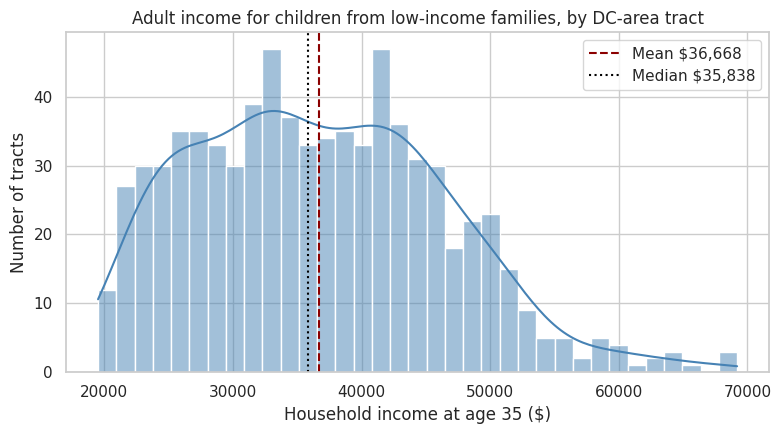

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df[TARGET], bins=35, kde=True, ax=ax, color='steelblue')
ax.axvline(df[TARGET].mean(), color='darkred', linestyle='--', label=f"Mean ${df[TARGET].mean():,.0f}")
ax.axvline(df[TARGET].median(), color='black', linestyle=':', label=f"Median ${df[TARGET].median():,.0f}")
ax.set_xlabel('Household income at age 35 ($)')
ax.set_ylabel('Number of tracts')
ax.set_title('Adult income for children from low-income families, by DC-area tract')
ax.legend()
plt.tight_layout()
plt.savefig('figures/target_distribution.png', dpi=150)
plt.show()

The target has a single peak and a mild right tail. Most tracts fall between \$25,000 and \$45,000, with a few high-opportunity tracts above \$60,000.

### Distribution of every feature

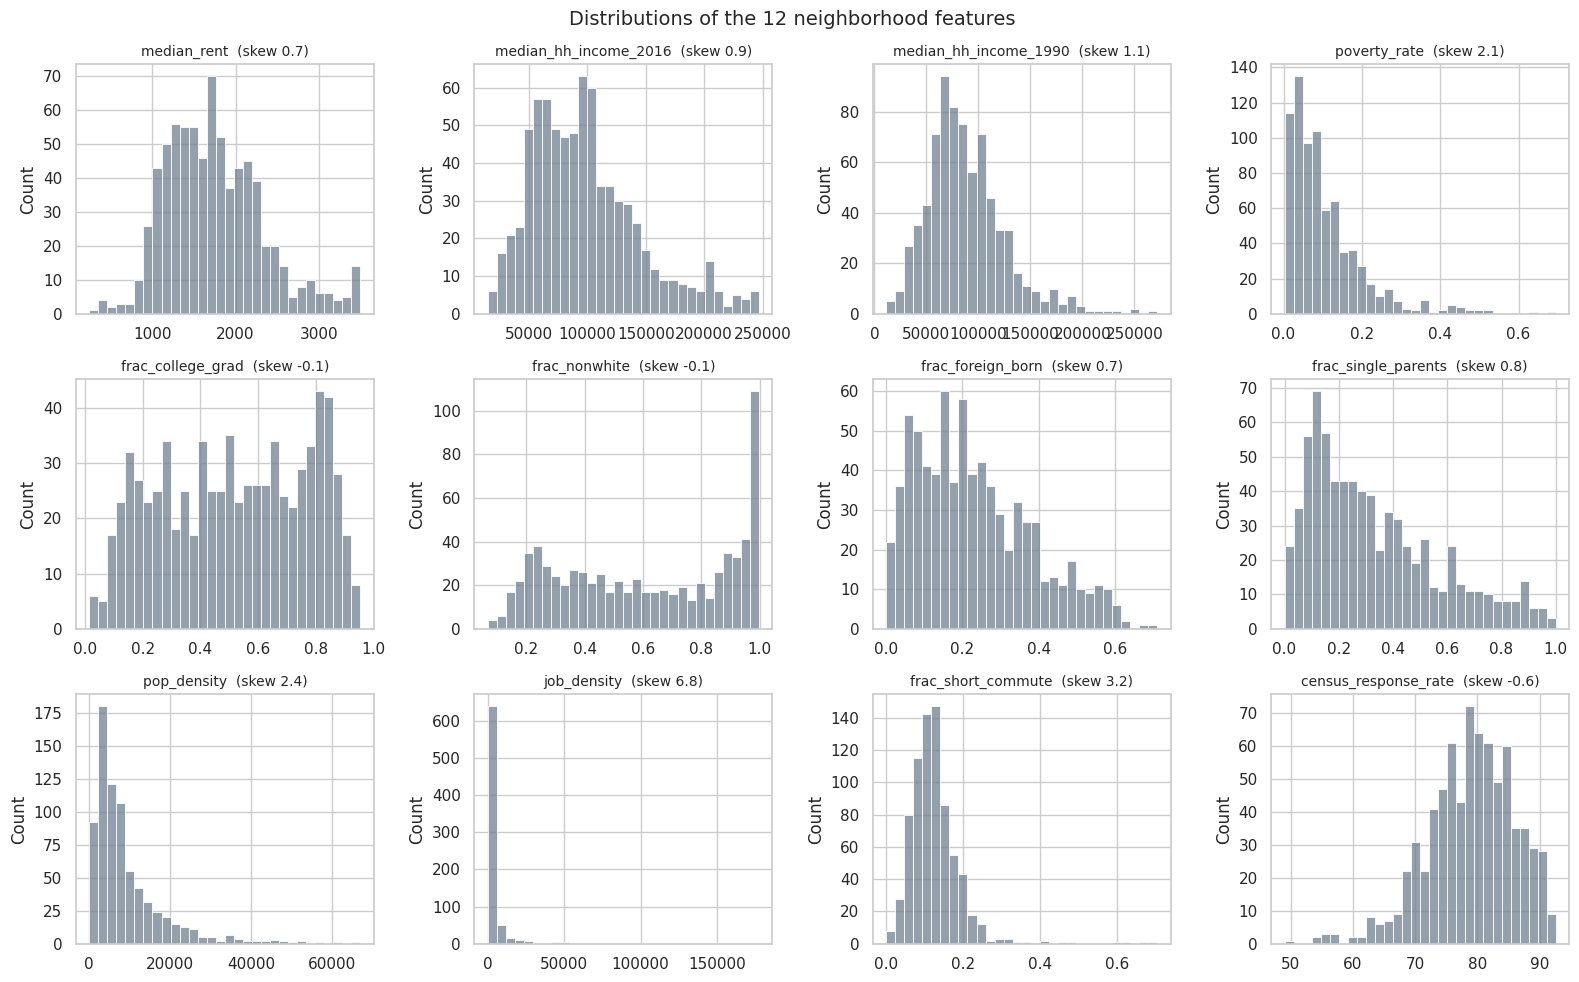

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, features):
    sns.histplot(df[col], bins=30, ax=ax, color='slategray')
    ax.set_title(f'{col}  (skew {df[col].skew():.1f})', fontsize=10)
    ax.set_xlabel('')
plt.suptitle('Distributions of the 12 neighborhood features', fontsize=14)
plt.tight_layout()
plt.savefig('figures/feature_distributions.png', dpi=150)
plt.show()

This confirms the profile table. The two **density** features are squeezed against zero with very long right tails, while the share features such as `frac_college_grad` and `frac_nonwhite` spread across their full 0-1 range.

### Income by state (subgroup comparison)

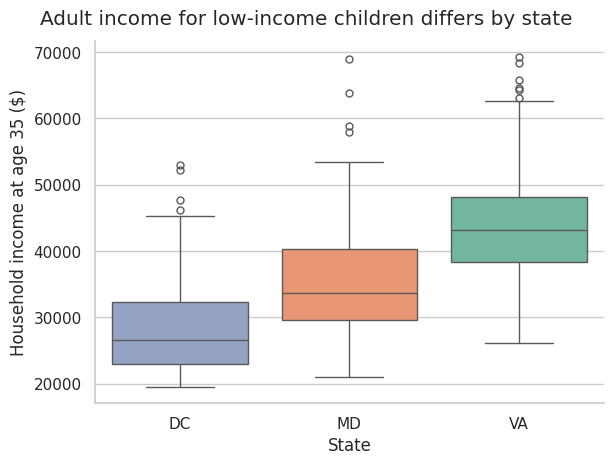

In [15]:
g = sns.catplot(data=df, x='state', y=TARGET, kind='box', order=['DC', 'MD', 'VA'],
                hue='state', palette='Set2', legend=False, height=4.5, aspect=1.4)
g.set_axis_labels('State', 'Household income at age 35 ($)')
g.fig.suptitle('Adult income for low-income children differs by state', y=1.03)
plt.savefig('figures/income_by_state.png', dpi=150, bbox_inches='tight')
plt.show()

The boxes barely overlap. The typical (median) Virginia tract sits above the upper quartile of DC tracts, which supports the ANOVA result.

### Income by neighborhood poverty level

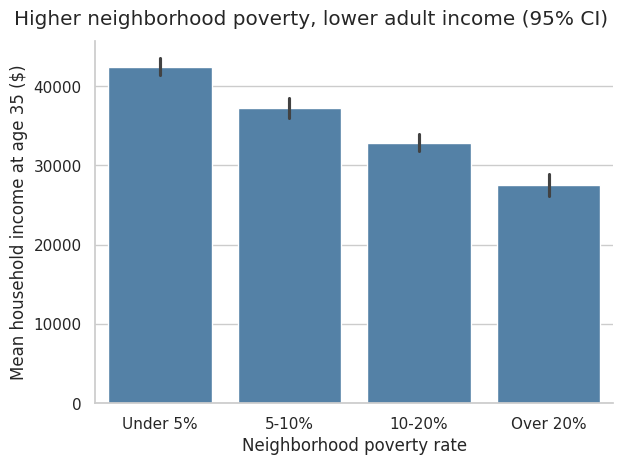

In [16]:
g = sns.catplot(data=df, x='poverty_group', y=TARGET, kind='bar', color='steelblue',
                errorbar=('ci', 95), height=4.5, aspect=1.4)
g.set_axis_labels('Neighborhood poverty rate', 'Mean household income at age 35 ($)')
g.fig.suptitle('Higher neighborhood poverty, lower adult income (95% CI)', y=1.03)
plt.savefig('figures/income_by_poverty_group.png', dpi=150, bbox_inches='tight')
plt.show()

### Each feature vs. the target (bi-plots)
Each scatter plot shows one feature against the target with a fitted regression line. The title shows its Pearson r.

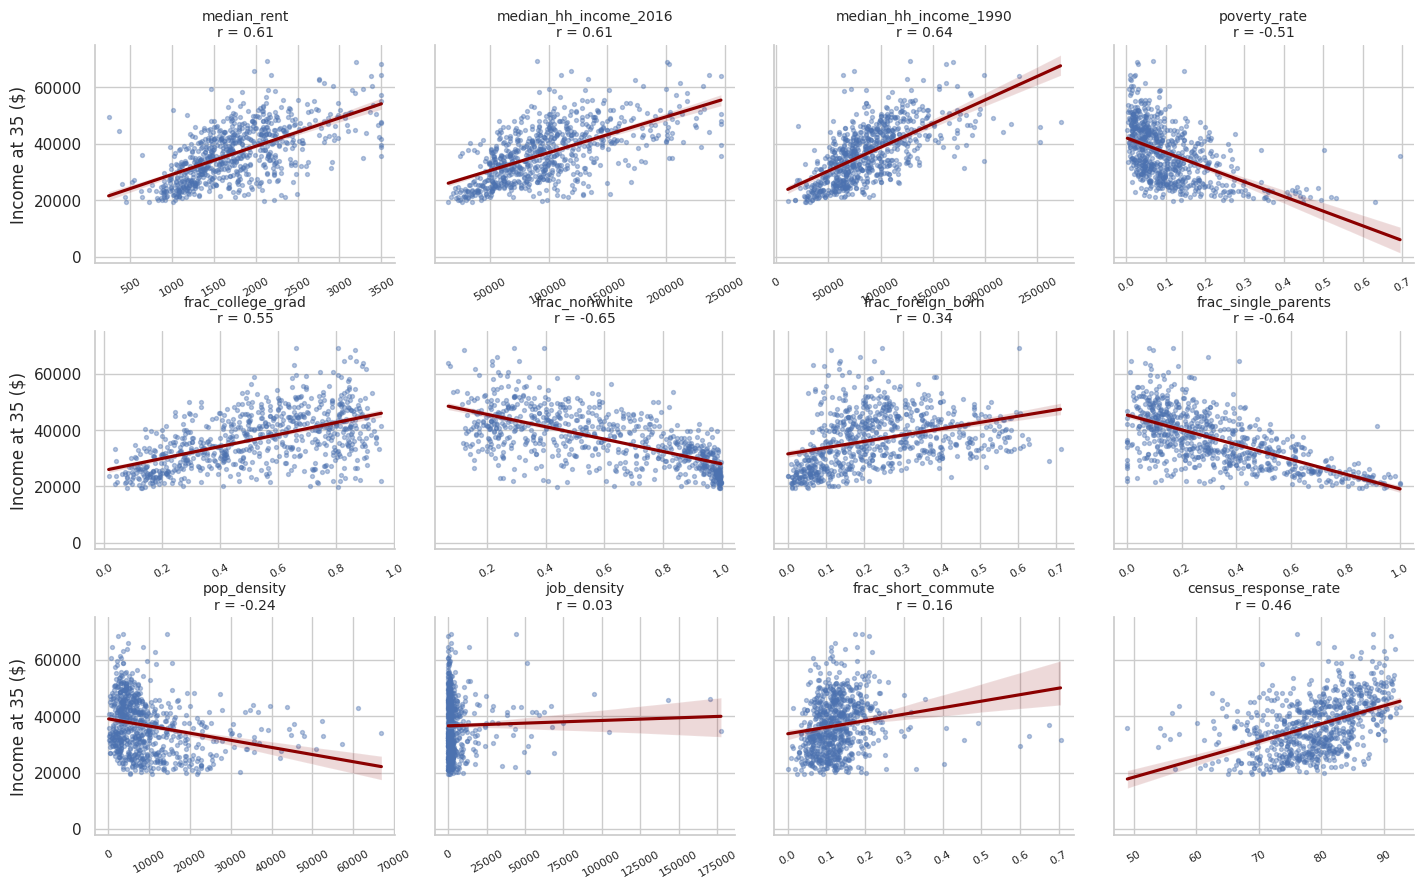

In [17]:
long = df.melt(id_vars=[TARGET], value_vars=features, var_name='feature', value_name='value')
g = sns.lmplot(data=long, x='value', y=TARGET, col='feature', col_wrap=4, height=3, aspect=1.2,
               facet_kws={'sharex': False}, scatter_kws={'s': 8, 'alpha': 0.4}, line_kws={'color': 'darkred'})
for ax, col in zip(g.axes.flat, g.col_names):
    ax.set_title(f"{col}\nr = {corr_table.loc[col, 'pearson_r']:.2f}", fontsize=10)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelrotation=30, labelsize=8)
g.set_ylabels('Income at 35 ($)')
plt.savefig('figures/features_vs_target.png', dpi=150, bbox_inches='tight')
plt.show()

**What the bi-plots show:**
- **Clear negative trends:** `frac_single_parents`, `frac_nonwhite` and `poverty_rate`. As these rise, adult income falls.
- **Clear positive trends:** both household income measures, `median_rent`, `frac_college_grad` and `census_response_rate`.
- **The density plots are hard to read.** Most points pile up on the left, which shows they need a log transform.
- **`job_density` shows a flat line**, matching its non-significant correlation test.

### Does a relationship hold within each state?
The state gap could be driving some of the correlations. Plotting `frac_single_parents`, one of the strongest features, separately by state shows whether the relationship holds inside each one.

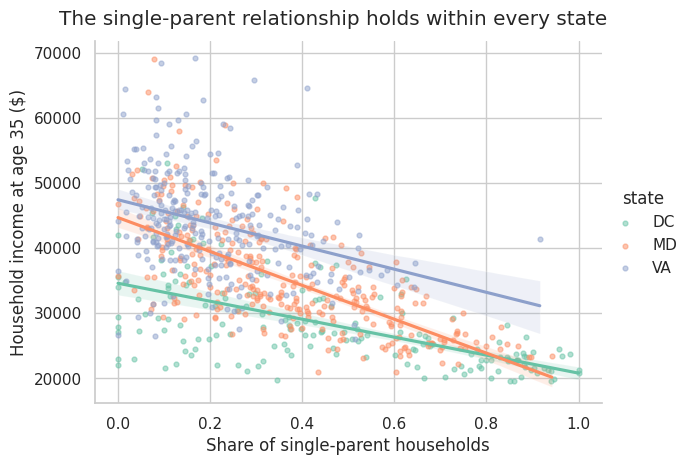

DC: r = -0.60, p = 2.22e-18
MD: r = -0.69, p = 8.34e-44
VA: r = -0.33, p = 2.96e-08


In [18]:
g = sns.lmplot(data=df, x='frac_single_parents', y=TARGET, hue='state', hue_order=['DC', 'MD', 'VA'],
               palette='Set2', height=4.5, aspect=1.4, scatter_kws={'s': 12, 'alpha': 0.5})
g.set_axis_labels('Share of single-parent households', 'Household income at age 35 ($)')
g.fig.suptitle('The single-parent relationship holds within every state', y=1.03)
plt.savefig('figures/single_parents_by_state.png', dpi=150, bbox_inches='tight')
plt.show()

for s in ['DC', 'MD', 'VA']:
    sub = df[df['state'] == s]
    r, p = stats.pearsonr(sub['frac_single_parents'], sub[TARGET])
    print(f'{s}: r = {r:.2f}, p = {p:.2e}')

The downward slope appears in all three states, so this isn't just a DC vs. Virginia difference. Neighborhood family structure matters within each state too.

### Correlation heatmap: relationships between all pairs of features

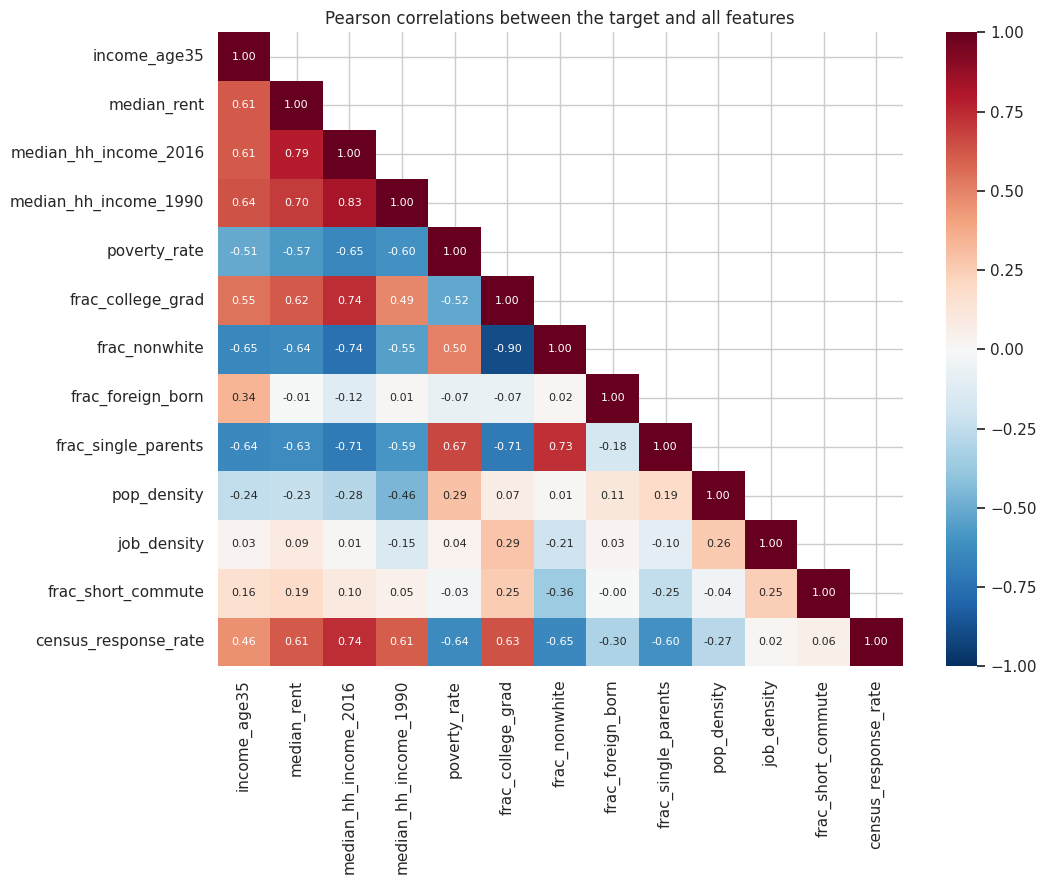

In [19]:
corr = df[[TARGET] + features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot_kws={'size': 8}, ax=ax)
ax.set_title('Pearson correlations between the target and all features')
plt.tight_layout()
plt.savefig('figures/correlation_heatmap.png', dpi=150)
plt.show()

In [20]:
# List the highly correlated pairs of independent variables (|r| > 0.7)
high_pairs = []
for i, a in enumerate(features):
    for b in features[i + 1:]:
        if abs(corr.loc[a, b]) > 0.7:
            high_pairs.append({'feature_1': a, 'feature_2': b, 'r': round(corr.loc[a, b], 3)})
pd.DataFrame(high_pairs).sort_values('r', key=abs, ascending=False)

,feature_1,feature_2,r
6,frac_college_grad,frac_nonwhite,-0.898
1,median_hh_income_2016,median_hh_income_1990,0.827
0,median_rent,median_hh_income_2016,0.789
3,median_hh_income_2016,frac_nonwhite,-0.744
5,median_hh_income_2016,census_response_rate,0.742
2,median_hh_income_2016,frac_college_grad,0.740
8,frac_nonwhite,frac_single_parents,0.727
4,median_hh_income_2016,frac_single_parents,-0.708
7,frac_college_grad,frac_single_parents,-0.708


**Several features are strongly correlated with each other (multicollinearity):**
- **`frac_college_grad` and `frac_nonwhite` (r = -0.90)** measure nearly the same pattern across tracts.
- **`median_hh_income_2016`** is strongly correlated (|r| > 0.7) with **six** other features: rent, 1990 income, college graduates, non-white share, single parents and census response.

When features overlap this much, a linear model can't separate their effects. Coefficients become unstable and hard to interpret. Section 3 deals with this.

## 3. Feature Selection and Engineering

### Missing data
The Data Wrangling notebook already handled missing data (dropped `job_growth`, dropped 4 tracts with no target, and filled 13 small gaps with county medians). A final check:

In [21]:
print('Missing values:', df[[TARGET] + features].isnull().sum().sum())

Missing values: 0


### Log-transforming the skewed density features
`pop_density` and `job_density` have very long right tails (skew 2.4 and 6.8). A log transform spreads out the low values and pulls in the extreme ones. I use `np.log1p()` (the log of 1 + value) because some tracts have 0 jobs, and log(0) is undefined.

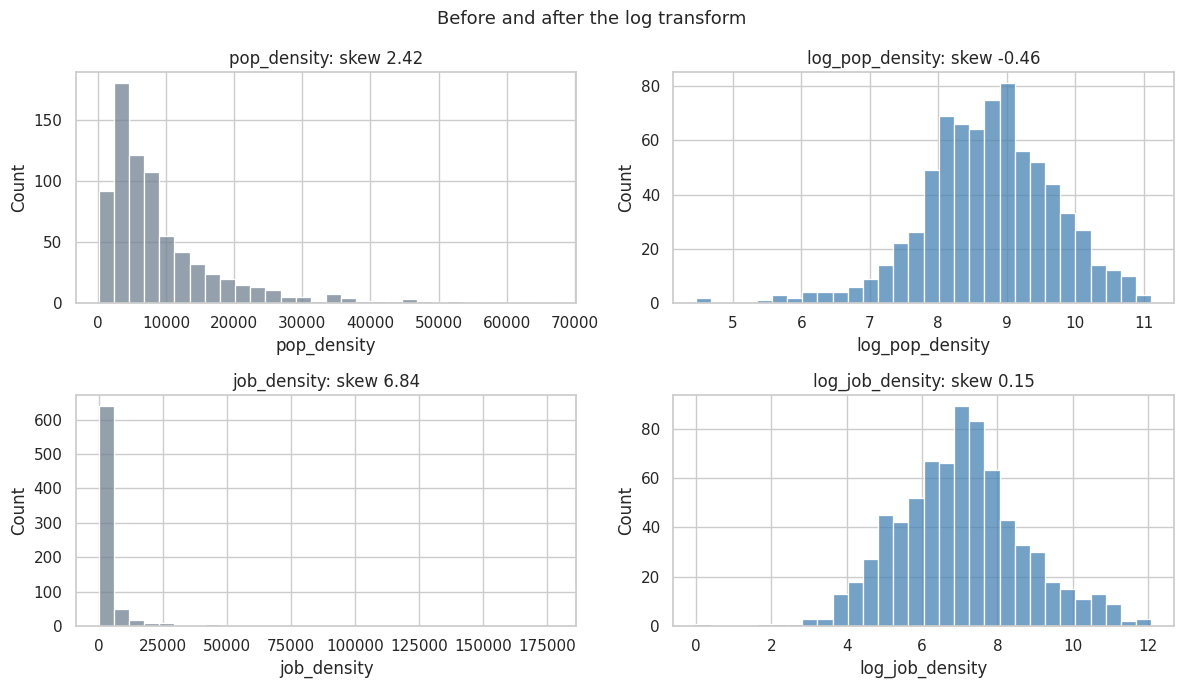

log_pop_density: r with target = -0.255, p = 0.000
log_job_density: r with target = -0.037, p = 0.309


In [22]:
for col in ['pop_density', 'job_density']:
    df[f'log_{col}'] = np.log1p(df[col])

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, col in enumerate(['pop_density', 'job_density']):
    sns.histplot(df[col], bins=30, ax=axes[row, 0], color='slategray')
    axes[row, 0].set_title(f'{col}: skew {df[col].skew():.2f}')
    sns.histplot(df[f'log_{col}'], bins=30, ax=axes[row, 1], color='steelblue')
    axes[row, 1].set_title(f'log_{col}: skew {df[f"log_{col}"].skew():.2f}')
plt.suptitle('Before and after the log transform', fontsize=13)
plt.tight_layout()
plt.savefig('figures/log_transform_density.png', dpi=150)
plt.show()

for col in ['log_pop_density', 'log_job_density']:
    r, p = stats.pearsonr(df[col], df[TARGET])
    print(f'{col}: r with target = {r:.3f}, p = {p:.3f}')

The log transform brings both skews close to 0 (about -0.5 and 0.2). `log_pop_density` keeps a significant negative relationship with the target (r ≈ -0.25). `log_job_density` still shows **no** relationship (r ≈ -0.04, p ≈ 0.31).

The other skewed features (`poverty_rate`, `frac_short_commute`) are shares bounded between 0 and 1, and their bi-plots show a reasonable linear trend, so they're left as they are.

### Checking multicollinearity with the Variance Inflation Factor (VIF)
The VIF measures how much of a feature can be predicted by the other features. A **VIF above 5** is a common warning sign that a feature overlaps too much with the others. I compute it with the standard formula VIF = 1 / (1 - R²), where R² comes from regressing each feature on all the others.

In [23]:
def compute_vif(data):
    X = (data - data.mean()) / data.std()
    vifs = {}
    for col in X.columns:
        y = X[col]
        others = np.column_stack([np.ones(len(X)), X.drop(columns=col)])
        coef = np.linalg.lstsq(others, y, rcond=None)[0]
        r2 = 1 - ((y - others @ coef) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        vifs[col] = 1 / (1 - r2)
    return pd.Series(vifs, name='VIF').sort_values(ascending=False).round(2)

candidate_features = ['median_rent', 'median_hh_income_2016', 'median_hh_income_1990', 'poverty_rate',
                      'frac_college_grad', 'frac_nonwhite', 'frac_foreign_born', 'frac_single_parents',
                      'log_pop_density', 'log_job_density', 'frac_short_commute', 'census_response_rate']
compute_vif(df[candidate_features])

,VIF
median_hh_income_2016,8.02
frac_college_grad,7.62
frac_nonwhite,7.20
median_hh_income_1990,4.77
frac_single_parents,3.60
census_response_rate,3.39
median_rent,2.89
poverty_rate,2.51
log_pop_density,2.25
log_job_density,1.81


Three features have a VIF above 5: **`median_hh_income_2016` (8.0), `frac_college_grad` (7.6) and `frac_nonwhite` (7.2)**.

### Feature selection decisions
| Feature | Decision | Data-supported reason |
|---|---|---|
| `median_hh_income_2016` | **Drop** | Highest VIF (8.0), correlated above 0.7 with six other features. `median_hh_income_1990` captures neighborhood income with a slightly stronger link to the target (r = 0.64 vs. 0.61), and it's measured closer to when these children were growing up. |
| `frac_college_grad` | **Drop** | VIF 7.6, and r = -0.90 with `frac_nonwhite`, so the two carry almost the same information. `frac_nonwhite` has the stronger relationship with the target (\|r\| = 0.65 vs. 0.55), so it's kept. |
| `log_job_density` | **Drop** | Not related to the target in any test (Pearson p ≈ 0.31, Spearman ρ ≈ -0.06), before or after the log transform. |
| `pop_density`, `job_density` (raw) | **Replace** | Replaced by their log versions. |
| `state` | **Keep (categorical)** | Significant differences between all three states (ANOVA and all pairwise tests). It will be **one-hot encoded** in the Pre-processing step, with DC as the baseline. |
| `county`, `name`, `tract` | **Keep as labels only** | Identifiers, not model features. |
| Target outliers (4 tracts) | **Keep** | Real high-opportunity neighborhoods, not errors. |

After these drops, I re-check the VIF:

In [24]:
selected_features = ['median_rent', 'median_hh_income_1990', 'poverty_rate', 'frac_nonwhite',
                     'frac_foreign_born', 'frac_single_parents', 'log_pop_density',
                     'frac_short_commute', 'census_response_rate']
compute_vif(df[selected_features])

,VIF
frac_nonwhite,3.75
frac_single_parents,3.39
census_response_rate,3.34
median_hh_income_1990,3.33
median_rent,2.54
poverty_rate,2.47
log_pop_density,2.01
frac_foreign_born,1.57
frac_short_commute,1.39


**Every VIF is now below 4**, so the remaining 9 features each bring mostly separate information. Together with `state`, they'll go into the model.

*Standardization isn't done here. It's part of the next step (Pre-processing), where the scaler is fit on the training data only.*

### Save the EDA feature set

In [25]:
eda_features = df[['tract', 'name', 'state', 'county', TARGET] + selected_features]
eda_features.to_csv('data/processed/eda_features.csv', index=False)
print('Saved data/processed/eda_features.csv:', eda_features.shape)
eda_features.head()

Saved data/processed/eda_features.csv: (752, 14)


,tract,name,state,county,income_age35,median_rent,median_hh_income_1990,poverty_rate,frac_nonwhite,frac_foreign_born,frac_single_parents,log_pop_density,frac_short_commute,census_response_rate
0,51059480203,"Tysons, VA",VA,"Fairfax County, VA",69199.0,2138.0,128382,0.0673,0.3958,0.6029,0.1672,9.565564,0.1916,76.2
1,24031701002,"Rockville, MD",MD,"Montgomery County, MD",69034.0,3193.0,169391,0.0262,0.2914,0.2444,0.0787,8.176110,0.1747,88.3
2,51013100400,"Arlington, VA",VA,"Arlington County, VA",68322.0,3501.0,162342,0.0286,0.1214,0.1138,0.0941,7.765993,0.2106,91.2
3,51013101601,"North Highland, Arlington, VA",VA,"Arlington County, VA",65785.0,1982.0,74114,0.1455,0.2323,0.1876,0.2963,8.496990,0.1230,79.5
4,51510200702,"Eisenhower East, Alexandria, VA",VA,"Alexandria city, VA",64583.0,2186.0,64247,0.0222,0.3072,0.1373,0.4101,9.041448,0.1798,82.1


## 4. Answers to the Outline's Questions

**Are there variables that are particularly significant in explaining the answer to the project question?**
Yes. The strongest relationships with adult income are:
- `frac_single_parents` (r = -0.64)
- `frac_nonwhite` (r = -0.65)
- `median_hh_income_1990` (r = +0.64)
- `median_rent` (r = +0.61)
- `poverty_rate` (r = -0.51)

All are significant at p < 0.001. Children from low-income families do better as adults in neighborhoods with fewer single-parent households, less poverty and higher incomes.

**Are there significant differences between subgroups that may be relevant to the project aim?**
Yes:
- **By state:** DC, Maryland and Virginia all differ significantly (ANOVA p < 0.001, and every pairwise test is significant). DC tracts average about \$15,500 less than Virginia tracts.
- **By poverty level:** high-poverty tracts average about \$8,900 less than low-poverty tracts (Welch's t-test p < 0.001).
- The single-parent relationship holds **within** each state, so it isn't just a state effect.

**Are there strong correlations between pairs of independent variables, or between an independent and the dependent variable?**
Both:
- **Between features:** `frac_college_grad` and `frac_nonwhite` (r = -0.90), and `median_hh_income_2016` with six other features (|r| > 0.7). This multicollinearity was resolved by dropping `median_hh_income_2016` and `frac_college_grad`, which brought every VIF below 4.
- **With the target:** several features have moderately strong correlations (|r| ≈ 0.5-0.65).

**What are the most appropriate tests to use to analyze these relationships?**
| Relationship | Test used | Why |
|---|---|---|
| Numeric feature vs. numeric target | Pearson correlation, confirmed with Spearman | Pearson measures linear strength. Spearman is robust to the skew found by Shapiro-Wilk. |
| Many features tested at once | Bonferroni correction | Guards against false positives from running 12 tests |
| Target across 3 states | One-way ANOVA (Levene's check), confirmed with Kruskal-Wallis | ANOVA compares 3+ group means. Kruskal-Wallis doesn't assume normality. |
| Which states differ | Pairwise Welch's t-tests with Bonferroni | Doesn't assume equal variances, and controls for multiple comparisons |
| High vs. low poverty tracts | Welch's t-test, confirmed with Mann-Whitney U | Compares two independent groups |
| Overlap between features | Correlation matrix and VIF | VIF measures how much each feature is explained by all the others |

## Summary
- **Profiles:** the target is mildly right-skewed (Shapiro-Wilk rejects normality), and 4 high outliers are real neighborhoods, so they were kept. The density features are heavily skewed.
- **Inferential statistics:** 11 of the 12 features are significantly correlated with adult income (`job_density` isn't). Income differs significantly by state (Virginia > Maryland > DC) and by poverty level.
- **Visualizations:** 8 figures were saved to `figures/` for the final report.
- **Feature engineering:** the two density features were log-transformed. Poverty was binned for exploration only.
- **Feature selection:** `median_hh_income_2016` and `frac_college_grad` were dropped for multicollinearity, and `log_job_density` was dropped for having no relationship with the target. `state` is kept for one-hot encoding in Pre-processing.
- **Output:** `data/processed/eda_features.csv` (752 tracts: ID columns, the target and 9 numeric features, plus `state`), ready for Pre-processing.